# Praktikum 4 — Implementasi Pencarian Terarah dan Heuristik dengan Python

**Mata Kuliah:** Kecerdasan Buatan (RPL3404) · **Program Studi:** D4 Teknologi Rekayasa Perangkat Lunak
**Jurusan Teknologi Informasi — Politeknik Negeri Padang** · Buku Ajar Bab 4: *Pencarian Terarah dan Heuristik*

| Identitas | Isian |
|---|---|
| Nama | Windi Sri Rahayu |
| NIM | 2611089002 |
| Kelas | TRPL Ak 1 |
| Tanggal praktikum | 5 Oktober 2026 |
| Tautan repositori Git | https://github.com/windyrahayu45/Kecerdasan-Buatan |

> Jalankan sel secara berurutan dari atas ke bawah (**Runtime → Run all** di Colab atau **Run All** di Jupyter/VS Code).
> Praktikum ini melanjutkan Praktikum 3; kode dasarnya disertakan kembali pada sel Persiapan agar notebook dapat berdiri sendiri.

## A. Tujuan Praktikum
1. Membuat fungsi heuristik h(n) untuk masalah pencarian rute dan memeriksa admissibility serta consistency-nya.
2. Mengimplementasikan kerangka best-first search dan menurunkannya menjadi UCS, greedy, A*, dan weighted A*.
3. Mengimplementasikan IDA* sebagai versi A* yang hemat memori.
4. Membandingkan kualitas heuristik h₁ dan h₂ pada 8-puzzle menggunakan effective branching factor.
5. Menganalisis pertukaran antara kualitas solusi, waktu, dan memori pada pencarian satisficing.

## B. Alat dan Bahan
- Python 3.10+ (pustaka standar: `heapq`, `math`, `random`, `statistics`, `time`)
- Opsional untuk tabel dan grafik: `pandas`, `matplotlib`, `networkx` (tersedia di Google Colab)
- Buku Ajar Bab 4, terutama Gambar 4.1 dan Tabel 4.4–4.7

## C. Alokasi Waktu (2 jam praktik)
| Kegiatan | Durasi |
|---|---|
| Pengantar dan penyiapan berkas dari Praktikum 3 | 10 menit |
| Langkah 1–2: fungsi heuristik dan pemeriksaannya | 20 menit |
| Langkah 3–4: best-first, greedy, A*, weighted A*, IDA* | 40 menit |
| Langkah 5–8: 8-puzzle, b*, dan eksperimen | 40 menit |
| Diskusi dan penyusunan kesimpulan | 10 menit |

## Persiapan — kode dasar dari Praktikum 3
Sel ini memuat kembali `PETA_SUMBAR`, kelas `Problem` dan `Node`, serta fungsi `expand` dan `path_states` dari Praktikum 3.
Ditambahkan pula `uniform_cost_search` versi Praktikum 3 yang dipakai untuk menghitung h*(n) pada Langkah 2.

In [1]:
from collections import deque
import heapq

PETA_SUMBAR = {
    "Padang":         {"Pariaman": 56, "Padang Panjang": 72, "Solok": 64, "Painan": 77},
    "Pariaman":       {"Padang": 56, "Lubuk Basung": 48, "Padang Panjang": 50},
    "Painan":         {"Padang": 77},
    "Lubuk Basung":   {"Pariaman": 48, "Bukittinggi": 56},
    "Padang Panjang": {"Padang": 72, "Pariaman": 50, "Batusangkar": 36, "Bukittinggi": 19},
    "Bukittinggi":    {"Padang Panjang": 19, "Lubuk Basung": 56, "Payakumbuh": 33},
    "Batusangkar":    {"Padang Panjang": 36, "Solok": 55, "Sawahlunto": 46, "Payakumbuh": 42},
    "Solok":          {"Padang": 64, "Batusangkar": 55, "Sawahlunto": 36},
    "Sawahlunto":     {"Solok": 36, "Batusangkar": 46, "Sijunjung": 50},
    "Payakumbuh":     {"Bukittinggi": 33, "Batusangkar": 42},
    "Sijunjung":      {"Sawahlunto": 50},
}

class Problem:
    """Masalah pencarian: initial state, goal, ACTIONS, RESULT, ACTION-COST."""
    def __init__(self, initial, goal, graph):
        self.initial, self.goal, self.graph = initial, goal, graph
    def actions(self, s):            # aksi = pindah ke kota tetangga
        return list(self.graph[s])
    def result(self, s, a):          # transition model
        return a
    def action_cost(self, s, a, s2):
        return self.graph[s][s2]
    def is_goal(self, s):
        return s == self.goal

class Node:
    def __init__(self, state, parent=None, action=None, path_cost=0):
        self.state, self.parent = state, parent
        self.action, self.path_cost = action, path_cost
        self.depth = 0 if parent is None else parent.depth + 1
    def __lt__(self, other):          # dibutuhkan heapq saat biaya sama
        return self.state < other.state

def expand(problem, node):
    s = node.state
    for a in problem.actions(s):
        s2 = problem.result(s, a)
        cost = node.path_cost + problem.action_cost(s, a, s2)
        yield Node(s2, node, a, cost)

def path_states(node):
    path = []
    while node is not None:
        path.append(node.state)
        node = node.parent
    return path[::-1]

def uniform_cost_search(problem, stats):
    """UCS dari Praktikum 3 — dipakai untuk menghitung biaya jalur optimal h*(n)."""
    node = Node(problem.initial)
    frontier = [(0, node)]
    reached = {problem.initial: node}
    while frontier:
        g, node = heapq.heappop(frontier)
        if g > reached[node.state].path_cost:
            continue
        if problem.is_goal(node.state):
            return node
        stats["expanded"] += 1
        for child in expand(problem, node):
            s = child.state
            if s not in reached or child.path_cost < reached[s].path_cost:
                reached[s] = child
                heapq.heappush(frontier, (child.path_cost, child))
    return None

print("Kode dasar Praktikum 3 siap:", len(PETA_SUMBAR), "kota")

Kode dasar Praktikum 3 siap: 11 kota


## D. Langkah Kerja

### Langkah 1 — Fungsi heuristik untuk peta Sumatera Barat
Heuristik yang dipakai adalah **jarak garis lurus** h_SLD ke kota tujuan, dihitung dari koordinat lintang dan bujur dengan
rumus haversine. Nilai h dibulatkan **ke bawah** dengan `int()` agar tidak melebih-lebihkan jarak jalan yang sebenarnya.

In [2]:
# ---- Langkah 1: fungsi heuristik untuk peta Sumatera Barat ----
import math
KOORDINAT = {
    "Padang":         (-0.9471, 100.4172), "Pariaman":     (-0.6266, 100.1206),
    "Painan":         (-1.3450, 100.5770), "Lubuk Basung": (-0.3000, 100.0300),
    "Padang Panjang": (-0.4670, 100.4000), "Bukittinggi":  (-0.3050, 100.3690),
    "Payakumbuh":     (-0.2290, 100.6300), "Batusangkar":  (-0.4460, 100.5920),
    "Solok":          (-0.7900, 100.6500), "Sawahlunto":   (-0.6820, 100.7790),
    "Sijunjung":      (-0.6870, 100.9530),
}

def jarak_garis_lurus(a, b):
    """Jarak garis lurus (haversine) antara dua kota dalam km."""
    R = 6371.0
    la1, lo1 = map(math.radians, KOORDINAT[a])
    la2, lo2 = map(math.radians, KOORDINAT[b])
    d = (math.sin((la2 - la1) / 2) ** 2
         + math.cos(la1) * math.cos(la2) * math.sin((lo2 - lo1) / 2) ** 2)
    return 2 * R * math.asin(math.sqrt(d))

def buat_h_sld(goal):
    """Membuat fungsi heuristik h(node) = jarak garis lurus ke goal (dibulatkan ke bawah)."""
    tabel = {kota: int(jarak_garis_lurus(kota, goal)) for kota in KOORDINAT}
    def h(node):
        return tabel[node.state]
    h.tabel = tabel                          # disimpan agar mudah ditampilkan
    return h

In [3]:
h = buat_h_sld("Sijunjung")
masalah = Problem("Padang", "Sijunjung", PETA_SUMBAR)

print("Nilai h(n) = jarak garis lurus ke Sijunjung (km):")
for kota, nilai in sorted(h.tabel.items(), key=lambda x: x[1]):
    print(f"  {kota:<16} {nilai:>4}")
print("\nContoh: jarak garis lurus Padang-Sijunjung =",
      round(jarak_garis_lurus("Padang", "Sijunjung"), 1), "km")

Nilai h(n) = jarak garis lurus ke Sijunjung (km):
  Sijunjung           0
  Sawahlunto         19
  Solok              35
  Batusangkar        48
  Payakumbuh         62
  Padang             66
  Padang Panjang     66
  Bukittinggi        77
  Painan             84
  Pariaman           92
  Lubuk Basung      111

Contoh: jarak garis lurus Padang-Sijunjung = 66.2 km


### Langkah 2 — Memeriksa admissibility dan consistency
Heuristik wajib diperiksa sebelum dipakai:

- **admissible** bila h(n) ≤ h*(n) untuk setiap n (h* = biaya jalur optimal sebenarnya, dihitung dengan UCS);
- **consistent** bila h(n) ≤ c(n, a, n′) + h(n′) untuk setiap aksi (ketaksamaan segitiga).

In [4]:
# ---- Langkah 2: memeriksa admissibility dan consistency ----
def periksa_heuristik(graph, tabel_h, h_bintang):
    """h admissible bila h(n) <= h*(n); consistent bila h(n) <= c(n,a,n') + h(n')."""
    laporan = {"admissible": True, "consistent": True, "pelanggaran": []}
    for kota in graph:
        if tabel_h[kota] > h_bintang[kota]:
            laporan["admissible"] = False
            laporan["pelanggaran"].append(
                f"admissible: h({kota})={tabel_h[kota]} > h*={h_bintang[kota]}")
    for a, tetangga in graph.items():
        for b, c in tetangga.items():
            if tabel_h[a] > c + tabel_h[b]:
                laporan["consistent"] = False
                laporan["pelanggaran"].append(
                    f"consistent: h({a})={tabel_h[a]} > {c} + h({b})={tabel_h[b]}")
    return laporan

In [5]:
# h*(n) dihitung dengan UCS dari setiap kota menuju Sijunjung
h_bintang = {}
for kota in PETA_SUMBAR:
    if kota == "Sijunjung":
        h_bintang[kota] = 0
    else:
        h_bintang[kota] = uniform_cost_search(Problem(kota, "Sijunjung", PETA_SUMBAR),
                                              {"expanded": 0}).path_cost

laporan = periksa_heuristik(PETA_SUMBAR, h.tabel, h_bintang)
print("admissible:", laporan["admissible"], "| consistent:", laporan["consistent"])
print("pelanggaran:", laporan["pelanggaran"] or "tidak ada")

print(f"\n{'Kota':<16}{'h(n)':>6}{'h*(n)':>8}{'selisih':>9}")
for kota in sorted(h.tabel, key=lambda k: h.tabel[k]):
    print(f"{kota:<16}{h.tabel[kota]:>6}{h_bintang[kota]:>8}{h_bintang[kota]-h.tabel[kota]:>9}")

admissible: True | consistent: True
pelanggaran: tidak ada

Kota              h(n)   h*(n)  selisih
Sijunjung            0       0        0
Sawahlunto          19      50       31
Solok               35      86       51
Batusangkar         48      96       48
Payakumbuh          62     138       76
Padang              66     150       84
Padang Panjang      66     132       66
Bukittinggi         77     151       74
Painan              84     227      143
Pariaman            92     182       90
Lubuk Basung       111     207       96


**Coba sendiri:** ubah `int(...)` pada `buat_h_sld` menjadi pembulatan ke atas (`math.ceil`), lalu jalankan ulang sel di atas.
Ruas mana yang menjadi tidak admissible? (Petunjuk: bandingkan jarak jalan dan jarak garis lurus Bukittinggi–Payakumbuh.)

### Langkah 3 — Best-first search dan turunannya
Satu kerangka `best_first_search` cukup untuk menghasilkan empat algoritma; yang berbeda hanya **evaluation function**-nya:

| Algoritma | f(n) |
|---|---|
| Uniform-cost search | g(n) |
| Greedy best-first search | h(n) |
| A* search | g(n) + h(n) |
| Weighted A* search | g(n) + W × h(n) |

In [6]:
# ---- Langkah 3: best-first search dan turunannya ----
def best_first_search(problem, f, stats):
    """Kerangka umum: meng-expand node dengan nilai f(node) terkecil."""
    node = Node(problem.initial)
    frontier = [(f(node), node)]                 # priority queue menurut f
    stats["max_frontier"] = max(stats.get("max_frontier", 0), len(frontier))
    reached = {problem.initial: node}
    while frontier:
        nilai, node = heapq.heappop(frontier)
        if nilai > f(reached[node.state]):
            continue                             # entri usang (lazy deletion)
        if problem.is_goal(node.state):
            return node
        stats["expanded"] += 1
        for child in expand(problem, node):
            s = child.state
            if s not in reached or child.path_cost < reached[s].path_cost:
                reached[s] = child
                heapq.heappush(frontier, (f(child), child))
                stats["max_frontier"] = max(stats.get("max_frontier", 0), len(frontier))
        stats["max_frontier"] = max(stats.get("max_frontier", 0), len(frontier))
    return None

def uniform_cost(problem, h, stats):
    """f(n) = g(n) — uniform-cost search; heuristik tidak dipakai."""
    return best_first_search(problem, lambda n: n.path_cost, stats)

def greedy_best_first_search(problem, h, stats):
    """f(n) = h(n)"""
    return best_first_search(problem, lambda n: h(n), stats)

def a_star_search(problem, h, stats):
    """f(n) = g(n) + h(n)"""
    return best_first_search(problem, lambda n: n.path_cost + h(n), stats)

def weighted_a_star_search(problem, h, W, stats):
    """f(n) = g(n) + W x h(n), dengan W > 1"""
    return best_first_search(problem, lambda n: n.path_cost + W * h(n), stats)

In [7]:
import pandas as pd

def ringkas(problem, h, daftar=None):
    daftar = daftar or [("UCS (f=g)", uniform_cost),
                        ("Greedy (f=h)", greedy_best_first_search),
                        ("A* (f=g+h)", a_star_search),
                        ("Weighted A* (W=2)", lambda p, h, s: weighted_a_star_search(p, h, 2, s))]
    baris = []
    for nama, f in daftar:
        stats = {"expanded": 0, "max_frontier": 0}
        hasil = f(problem, h, stats)
        baris.append({"Algoritma": nama,
                      "Rute": " - ".join(path_states(hasil)),
                      "Langkah": hasil.depth, "Biaya (km)": hasil.path_cost,
                      "Node di-expand": stats["expanded"],
                      "Frontier maks": stats["max_frontier"]})
    return pd.DataFrame(baris)

ringkas(masalah, h)

,Algoritma,Rute,Langkah,Biaya (km),Node di-expand,Frontier maks
0,UCS (f=g),Padang - Solok - Sawahlunto - Sijunjung,3,150,10,6
1,Greedy (f=h),Padang - Solok - Sawahlunto - Sijunjung,3,150,3,5
2,A* (f=g+h),Padang - Solok - Sawahlunto - Sijunjung,3,150,5,6
3,Weighted A* (W=2),Padang - Solok - Sawahlunto - Sijunjung,3,150,3,5


**Penelusuran greedy dan A\*.** Sel berikut mencetak isi frontier setiap iterasi agar dapat dibandingkan dengan
Tabel 4.2 dan Tabel 4.3 pada Buku Ajar.

In [8]:
def telusuri(problem, f, label):
    print("==", label)
    node = Node(problem.initial)
    frontier = [(f(node), node)]
    reached = {problem.initial: node}
    iterasi = 0
    while frontier:
        nilai, node = heapq.heappop(frontier)
        if nilai > f(reached[node.state]):
            continue
        if problem.is_goal(node.state):
            print(f"{iterasi+1:>2}. ambil {node.state} (f={nilai}) -> GOAL, biaya={node.path_cost} km")
            return node
        iterasi += 1
        for child in expand(problem, node):
            s = child.state
            if s not in reached or child.path_cost < reached[s].path_cost:
                reached[s] = child
                heapq.heappush(frontier, (f(child), child))
        isi = sorted((v, n.state) for v, n in frontier if v <= f(reached[n.state]))
        print(f"{iterasi:>2}. expand {node.state} (f={nilai}) | frontier: "
              + ", ".join(f"{s} {v}" for v, s in isi))
    return None

_ = telusuri(masalah, lambda n: h(n), "GREEDY  f(n) = h(n)")
print()
_ = telusuri(masalah, lambda n: n.path_cost + h(n), "A*  f(n) = g(n) + h(n)")

== GREEDY  f(n) = h(n)
 1. expand Padang (f=66) | frontier: Solok 35, Padang Panjang 66, Painan 84, Pariaman 92
 2. expand Solok (f=35) | frontier: Sawahlunto 19, Batusangkar 48, Padang Panjang 66, Painan 84, Pariaman 92
 3. expand Sawahlunto (f=19) | frontier: Sijunjung 0, Batusangkar 48, Padang Panjang 66, Painan 84, Pariaman 92
 4. ambil Sijunjung (f=0) -> GOAL, biaya=150 km

== A*  f(n) = g(n) + h(n)
 1. expand Padang (f=66) | frontier: Solok 99, Padang Panjang 138, Pariaman 148, Painan 161
 2. expand Solok (f=99) | frontier: Sawahlunto 119, Padang Panjang 138, Pariaman 148, Painan 161, Batusangkar 167
 3. expand Sawahlunto (f=119) | frontier: Padang Panjang 138, Pariaman 148, Sijunjung 150, Painan 161, Batusangkar 167
 4. expand Padang Panjang (f=138) | frontier: Pariaman 148, Sijunjung 150, Batusangkar 156, Painan 161, Bukittinggi 168
 5. expand Pariaman (f=148) | frontier: Sijunjung 150, Batusangkar 156, Painan 161, Bukittinggi 168, Lubuk Basung 215
 6. ambil Sijunjung (f=150) -

**Pertanyaan analisis Langkah 3** (jawab pada sel Markdown di bawah):
1. Pada iterasi ke berapa greedy dan A* mengambil keputusan yang berbeda? Node apa yang dipilih masing-masing dan mengapa?
2. Node mana saja yang **tidak pernah** di-expand oleh A*? Kaitkan dengan konsep pruning dan nilai C*.

*Jawaban:*

1. Keputusan pertama yang berbeda terjadi setelah Sawahlunto di-expand. Greedy memilih Sijunjung (h=0) dan langsung menerima goal, sedangkan A* memilih Padang Panjang (f=138) lebih dahulu karena nilai f-nya lebih kecil daripada Sijunjung (f=150). A* kemudian meng-expand Pariaman (f=148) sebelum mengambil Sijunjung.
2. Dengan C*=150 km, A* meng-expand Padang, Solok, Sawahlunto, Padang Panjang, dan Pariaman. Node yang tidak di-expand ialah Painan, Batusangkar, Bukittinggi, Lubuk Basung, Payakumbuh, dan Sijunjung (Sijunjung diambil sebagai goal, bukan di-expand). Sebagian node belum dibangkitkan ketika goal diambil; node frontier dengan f>C* tidak perlu diekspansi karena tidak dapat menghasilkan solusi yang lebih baik. Sijunjung pada f=C* adalah solusi optimal.

### Langkah 4 — Iterative-deepening A* (IDA*)
Batas setiap iterasi adalah nilai **f**, bukan kedalaman. Nilai f terkecil yang melampaui batas menjadi batas iterasi berikutnya.
IDA* tidak menyimpan tabel `reached` sama sekali, sehingga memorinya linear.

In [9]:
# ---- Langkah 4: iterative-deepening A* (IDA*) ----
def ida_star_search(problem, h, stats):
    """A* dengan memori linear: batas iterasi berupa f-cost, bukan kedalaman."""
    akar = Node(problem.initial)
    batas = h(akar)
    while True:
        stats["iterasi"] = stats.get("iterasi", 0) + 1
        hasil, batas_baru = _cari_terbatas_f(problem, akar, batas, h, stats)
        if hasil is not None:
            return hasil
        if batas_baru == math.inf:
            return None                          # tidak ada solusi
        batas = batas_baru                       # kontur f berikutnya

def _cari_terbatas_f(problem, node, batas, h, stats, kedalaman=1):
    stats["max_frontier"] = max(stats.get("max_frontier", 0), kedalaman)
    f = node.path_cost + h(node)
    if f > batas:
        return None, f                           # calon batas iterasi berikutnya
    if problem.is_goal(node.state):
        return node, batas
    stats["expanded"] += 1
    minimum = math.inf
    for child in expand(problem, node):
        if _siklus(child):
            continue
        hasil, nilai = _cari_terbatas_f(problem, child, batas, h, stats, kedalaman + 1)
        if hasil is not None:
            return hasil, batas
        minimum = min(minimum, nilai)
    return None, minimum

def _siklus(node):
    s, p = node.state, node.parent
    while p is not None:
        if p.state == s:
            return True
        p = p.parent
    return False

In [10]:
stats = {"expanded": 0, "max_frontier": 0}
hasil = ida_star_search(masalah, h, stats)
print("Rute :", " -> ".join(path_states(hasil)))
print("Biaya:", hasil.path_cost, "km | ekspansi:", stats["expanded"],
      "| iterasi:", stats["iterasi"], "| frontier tersimpan:", stats["max_frontier"])

Rute : Padang -> Solok -> Sawahlunto -> Sijunjung
Biaya: 150 km | ekspansi: 20 | iterasi: 6 | frontier tersimpan: 4


### Langkah 5 — 8-puzzle dan fungsi heuristiknya
Kelas `EightPuzzle` sama dengan Praktikum 3. Yang baru adalah tiga fungsi heuristik:
`h0` (nol), `h1` (jumlah ubin salah tempat), dan `h2` (jarak Manhattan).

In [11]:
# ---- Langkah 5: 8-puzzle dan fungsi heuristiknya ----
class EightPuzzle(Problem):
    GOAL = (1, 2, 3, 4, 5, 6, 7, 8, 0)           # 0 = ubin kosong
    GESER = {"Atas": -3, "Bawah": 3, "Kiri": -1, "Kanan": 1}
    def __init__(self, initial):
        self.initial, self.goal = tuple(initial), self.GOAL
    def actions(self, s):
        i = s.index(0)
        aksi = []
        if i >= 3: aksi.append("Atas")
        if i <= 5: aksi.append("Bawah")
        if i % 3 > 0: aksi.append("Kiri")
        if i % 3 < 2: aksi.append("Kanan")
        return aksi
    def result(self, s, a):
        i = s.index(0); j = i + self.GESER[a]
        s = list(s); s[i], s[j] = s[j], s[i]
        return tuple(s)
    def action_cost(self, s, a, s2):
        return 1

def h0_nol(node):
    """Heuristik nol: A* dengan h = 0 berperilaku seperti uniform-cost search."""
    return 0

def h1_salah_tempat(node):
    """h1 = jumlah ubin yang salah tempat (ubin kosong tidak dihitung)."""
    return sum(1 for i, v in enumerate(node.state)
               if v != 0 and v != EightPuzzle.GOAL[i])

def h2_manhattan(node):
    """h2 = jumlah jarak Manhattan setiap ubin ke posisi tujuannya."""
    total = 0
    for i, v in enumerate(node.state):
        if v == 0:
            continue
        tujuan = EightPuzzle.GOAL.index(v)
        total += abs(i // 3 - tujuan // 3) + abs(i % 3 - tujuan % 3)
    return total

In [12]:
def cetak_papan(s):
    for r in range(3):
        print(" ".join("_" if v == 0 else str(v) for v in s[3*r:3*r+3]))

BERAT = (1, 8, 3, 5, 0, 6, 4, 2, 7)          # state "berat" dari Praktikum 3
cetak_papan(BERAT)
n = Node(BERAT)
print("\nh1 =", h1_salah_tempat(n), "| h2 =", h2_manhattan(n))

# Rincian perhitungan h2 (bandingkan dengan Tabel 4.5 Buku Ajar)
print(f"\n{'Ubin':>5}{'posisi':>10}{'tujuan':>10}{'Manhattan':>11}")
for i, v in enumerate(BERAT):
    if v == 0:
        continue
    t = EightPuzzle.GOAL.index(v)
    d = abs(i // 3 - t // 3) + abs(i % 3 - t % 3)
    print(f"{v:>5}{str((i//3, i%3)):>10}{str((t//3, t%3)):>10}{d:>11}")

1 8 3
5 _ 6
4 2 7

h1 = 5 | h2 = 8

 Ubin    posisi    tujuan  Manhattan
    1    (0, 0)    (0, 0)          0
    8    (0, 1)    (2, 1)          2
    3    (0, 2)    (0, 2)          0
    5    (1, 0)    (1, 1)          1
    6    (1, 2)    (1, 2)          0
    4    (2, 0)    (1, 0)          1
    2    (2, 1)    (0, 1)          2
    7    (2, 2)    (2, 0)          2


In [13]:
# Bandingkan ketiga heuristik pada instans yang sama
import time
baris = []
for nama, hf in [("h = 0 (UCS)", h0_nol), ("h1 salah tempat", h1_salah_tempat),
                 ("h2 Manhattan", h2_manhattan)]:
    stats = {"expanded": 0, "max_frontier": 0}
    t0 = time.perf_counter()
    hasil = a_star_search(EightPuzzle(BERAT), hf, stats)
    dt = (time.perf_counter() - t0) * 1000
    baris.append({"Heuristik": nama, "Langkah": hasil.depth,
                  "Node di-expand": stats["expanded"],
                  "Frontier maks": stats["max_frontier"], "Waktu (ms)": round(dt, 1)})
stats = {"expanded": 0, "max_frontier": 0}
t0 = time.perf_counter()
hasil = ida_star_search(EightPuzzle(BERAT), h2_manhattan, stats)
baris.append({"Heuristik": "IDA* dengan h2", "Langkah": hasil.depth,
              "Node di-expand": stats["expanded"], "Frontier maks": stats["max_frontier"],
              "Waktu (ms)": round((time.perf_counter() - t0) * 1000, 1)})
pd.DataFrame(baris)

,Heuristik,Langkah,Node di-expand,Frontier maks,Waktu (ms)
0,h = 0 (UCS),14,4149,2368,96.2
1,h1 salah tempat,14,237,144,4.1
2,h2 Manhattan,14,56,40,1.3
3,IDA* dengan h2,14,74,15,1.2


### Langkah 6 — Effective branching factor
b* adalah branching factor yang harus dimiliki pohon seragam berkedalaman d agar memuat N + 1 node:

$$N + 1 = 1 + b^{*} + (b^{*})^{2} + \dots + (b^{*})^{d}$$

Makin dekat b* ke 1, makin baik heuristiknya.

In [14]:
# ---- Langkah 6: effective branching factor ----
def effective_branching_factor(N, d, toleransi=1e-6):
    """Mencari b* dari N = b* + (b*)^2 + ... + (b*)^d dengan metode bagi dua."""
    if d == 0:
        return 0.0
    def total(b):
        return sum(b ** i for i in range(1, d + 1))
    lo, hi = 1.0000001, 100.0
    while hi - lo > toleransi:
        tengah = (lo + hi) / 2
        if total(tengah) < N:
            lo = tengah
        else:
            hi = tengah
    return round((lo + hi) / 2, 2)

In [15]:
print("Uji: A* menemukan solusi pada d = 5 dengan 52 node ->",
      effective_branching_factor(52, 5), "(seharusnya 1.92)")

stats = {"expanded": 0}
hasil = a_star_search(EightPuzzle(BERAT), h2_manhattan, stats)
print("Instans BERAT dengan h2: d =", hasil.depth, ", N =", stats["expanded"],
      ", b* =", effective_branching_factor(stats["expanded"], hasil.depth))

Uji: A* menemukan solusi pada d = 5 dengan 52 node -> 1.92 (seharusnya 1.92)
Instans BERAT dengan h2: d = 14 , N = 56 , b* = 1.17


### Langkah 7 — Eksperimen pada peta Sumatera Barat
Template praktikum dosen menggunakan rute Padang–Payakumbuh. Pada notebook ini, graph diperluas dengan Sijunjung dan tujuan pencarian diubah menjadi Sijunjung, mengikuti uji mandiri pada Praktikum 3. Seluruh hasil di bawah menggunakan rute Padang–Sijunjung.

In [16]:
tabel_peta = ringkas(masalah, h, [
    ("UCS (f=g)", uniform_cost),
    ("Greedy (f=h)", greedy_best_first_search),
    ("A* (f=g+h)", a_star_search),
    ("Weighted A* (W=2)", lambda p, hh, s: weighted_a_star_search(p, hh, 2, s)),
    ("IDA*", ida_star_search),
])
tabel_peta

,Algoritma,Rute,Langkah,Biaya (km),Node di-expand,Frontier maks
0,UCS (f=g),Padang - Solok - Sawahlunto - Sijunjung,3,150,10,6
1,Greedy (f=h),Padang - Solok - Sawahlunto - Sijunjung,3,150,3,5
2,A* (f=g+h),Padang - Solok - Sawahlunto - Sijunjung,3,150,5,6
3,Weighted A* (W=2),Padang - Solok - Sawahlunto - Sijunjung,3,150,3,5
4,IDA*,Padang - Solok - Sawahlunto - Sijunjung,3,150,20,4


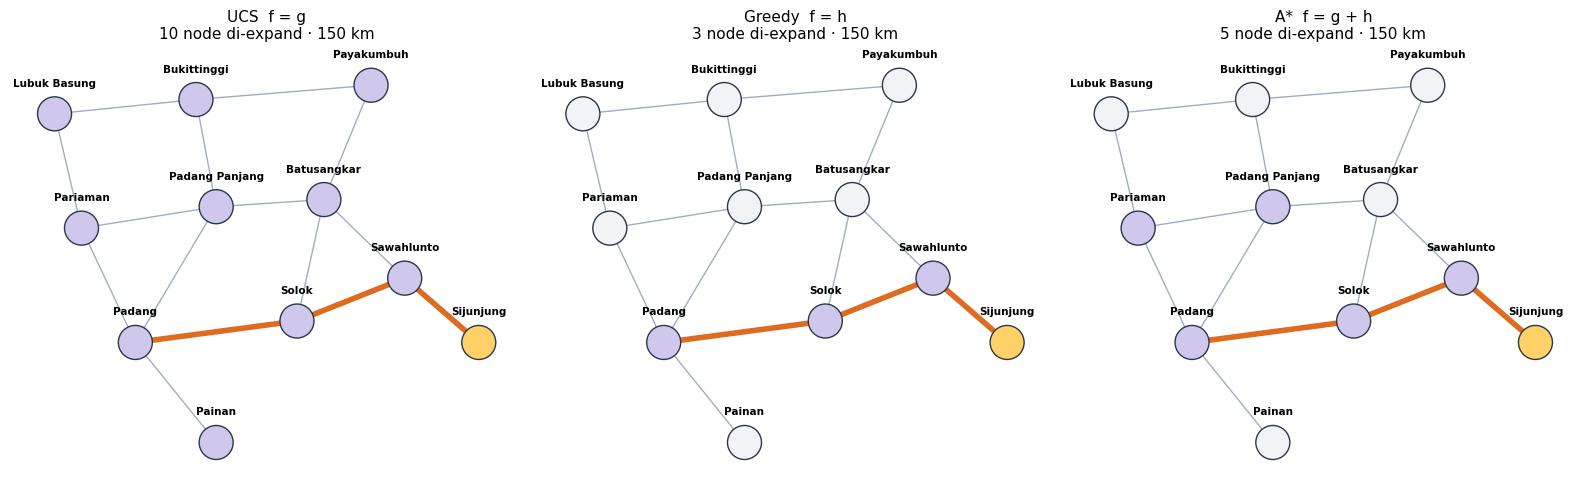

In [17]:
# Visualisasi: node yang di-expand oleh UCS, greedy, dan A*
import matplotlib.pyplot as plt
try:
    import networkx as nx
except ModuleNotFoundError:
    import subprocess
    import sys
    subprocess.check_call([sys.executable, "-m", "pip", "install", "networkx"])
    import networkx as nx

POSISI = {"Lubuk Basung": (0.2, 4.2), "Pariaman": (0.6, 2.6), "Padang": (1.4, 1.0),
          "Painan": (2.6, -0.4), "Padang Panjang": (2.6, 2.9), "Bukittinggi": (2.3, 4.4),
          "Payakumbuh": (4.9, 4.6), "Batusangkar": (4.2, 3.0), "Solok": (3.8, 1.3),
          "Sawahlunto": (5.4, 1.9), "Sijunjung": (6.5, 1.0)}

def jalankan_catat(problem, f):
    """Menjalankan best-first search sambil mencatat urutan node yang di-expand."""
    node = Node(problem.initial)
    frontier = [(f(node), node)]
    reached = {problem.initial: node}
    diexpand = []
    while frontier:
        v, node = heapq.heappop(frontier)
        if v > f(reached[node.state]):
            continue
        if problem.is_goal(node.state):
            return diexpand, path_states(node), node.path_cost
        diexpand.append(node.state)
        for child in expand(problem, node):
            s = child.state
            if s not in reached or child.path_cost < reached[s].path_cost:
                reached[s] = child
                heapq.heappush(frontier, (f(child), child))
    return diexpand, None, None

G = nx.Graph()
for a, nb in PETA_SUMBAR.items():
    for b, w in nb.items():
        G.add_edge(a, b, weight=w)

skema = [("UCS  f = g", lambda n: n.path_cost),
         ("Greedy  f = h", lambda n: h(n)),
         ("A*  f = g + h", lambda n: n.path_cost + h(n))]
fig, axes = plt.subplots(1, 3, figsize=(16, 5))
for ax, (judul, f) in zip(axes, skema):
    ex, rute, biaya = jalankan_catat(masalah, f)
    warna = ["#FFD166" if n == masalah.goal else "#CFC8EC" if n in ex else "#F1F3F6" for n in G]
    nx.draw_networkx_edges(G, POSISI, ax=ax, edge_color="#A0AEC0")
    nx.draw_networkx_edges(G, POSISI, edgelist=list(zip(rute, rute[1:])), ax=ax,
                           edge_color="#DD6B20", width=4)
    nx.draw_networkx_nodes(G, POSISI, ax=ax, node_color=warna, node_size=600, edgecolors="#2D3748")
    nx.draw_networkx_labels(G, {k: (x, y + 0.42) for k, (x, y) in POSISI.items()},
                            font_size=7.5, font_weight="bold", ax=ax)
    ax.set_title(f"{judul}\n{len(ex)} node di-expand · {biaya} km", fontsize=11)
    ax.axis("off")
plt.tight_layout()
plt.show()

### Langkah 8 — Eksperimen kualitas heuristik pada 8-puzzle
Instans dibangkitkan dengan mengacak langkah dari goal state (sehingga pasti dapat diselesaikan), lalu disaring agar
kedalaman solusi optimalnya tepat sesuai target. **Nilai seed dituliskan agar hasilnya dapat direproduksi.**

In [18]:
# ---- Langkah 8: eksperimen heuristik pada 8-puzzle ----
import random, statistics

def instans_acak(d, n, seed):
    """Membangkitkan n instans 8-puzzle yang solusi optimalnya tepat d langkah."""
    rng = random.Random(seed)
    contoh = EightPuzzle(EightPuzzle.GOAL)
    hasil = []
    while len(hasil) < n:
        s = EightPuzzle.GOAL
        for _ in range(rng.randint(d, d * 4)):          # acak dari goal: pasti solvable
            s = contoh.result(s, rng.choice(contoh.actions(s)))
        stats = {"expanded": 0}
        solusi = a_star_search(EightPuzzle(s), h2_manhattan, stats)
        if solusi.depth == d and s not in hasil:
            hasil.append(s)
    return hasil

def eksperimen_heuristik(kedalaman=(6, 10, 14, 18, 22), n=5, seed=20260925):
    print(f"{'d':>3} | {'UCS (h=0)':>10} {'A*(h1)':>9} {'A*(h2)':>8} | "
          f"{'b* UCS':>7} {'b* h1':>6} {'b* h2':>6}")
    for d in kedalaman:
        kasus = instans_acak(d, n, seed + d)
        rata = {}
        for nama, h in [("UCS", h0_nol), ("h1", h1_salah_tempat), ("h2", h2_manhattan)]:
            jumlah = []
            for s in kasus:
                stats = {"expanded": 0}
                a_star_search(EightPuzzle(s), h, stats)
                jumlah.append(stats["expanded"])
            m = statistics.mean(jumlah)
            rata[nama] = (round(m), effective_branching_factor(m, d))
        print(f"{d:>3} | {rata['UCS'][0]:>10} {rata['h1'][0]:>9} {rata['h2'][0]:>8} | "
              f"{rata['UCS'][1]:>7} {rata['h1'][1]:>6} {rata['h2'][1]:>6}")

def eksperimen_satisficing(d=22, n=5, seed=20260925):
    kasus = instans_acak(d, n, seed + d)
    print(f"{'Algoritma':<14} {'ekspansi':>9} {'biaya':>7} {'frontier':>9}")
    daftar = [("A* (W=1)", lambda p, s: a_star_search(p, h2_manhattan, s)),
              ("WA* W=1,5", lambda p, s: weighted_a_star_search(p, h2_manhattan, 1.5, s)),
              ("WA* W=2", lambda p, s: weighted_a_star_search(p, h2_manhattan, 2, s)),
              ("WA* W=3", lambda p, s: weighted_a_star_search(p, h2_manhattan, 3, s)),
              ("WA* W=5", lambda p, s: weighted_a_star_search(p, h2_manhattan, 5, s)),
              ("Greedy (h2)", lambda p, s: greedy_best_first_search(p, h2_manhattan, s))]
    for nama, f in daftar:
        ek, bi, fr = [], [], []
        for s in kasus:
            stats = {"expanded": 0, "max_frontier": 0}
            hasil = f(EightPuzzle(s), stats)
            ek.append(stats["expanded"]); bi.append(hasil.path_cost); fr.append(stats["max_frontier"])
        print(f"{nama:<14} {statistics.mean(ek):>9.0f} {statistics.mean(bi):>7.1f} "
              f"{statistics.mean(fr):>9.0f}")

In [19]:
print("A. Pengaruh kualitas heuristik (rata-rata 5 instans per kedalaman)")
eksperimen_heuristik()
print("\nB. Pencarian satisficing pada instans d = 22")
eksperimen_satisficing()

A. Pengaruh kualitas heuristik (rata-rata 5 instans per kedalaman)
  d |  UCS (h=0)    A*(h1)   A*(h2) |  b* UCS  b* h1  b* h2
  6 |         69         7        6 |    1.77   1.05    1.0
 10 |        507        26       12 |    1.71   1.17   1.04
 14 |       3432       173       55 |    1.68    1.3   1.17
 18 |      21865      1000       91 |    1.65   1.36   1.15
 22 |      78748      6049      485 |     1.6    1.4   1.23

B. Pencarian satisficing pada instans d = 22
Algoritma       ekspansi   biaya  frontier
A* (W=1)             485    22.0       288
WA* W=1,5            382    22.0       243
WA* W=2              354    23.2       231
WA* W=3              276    25.2       183
WA* W=5              189    32.0       128
Greedy (h2)          465    52.0       270


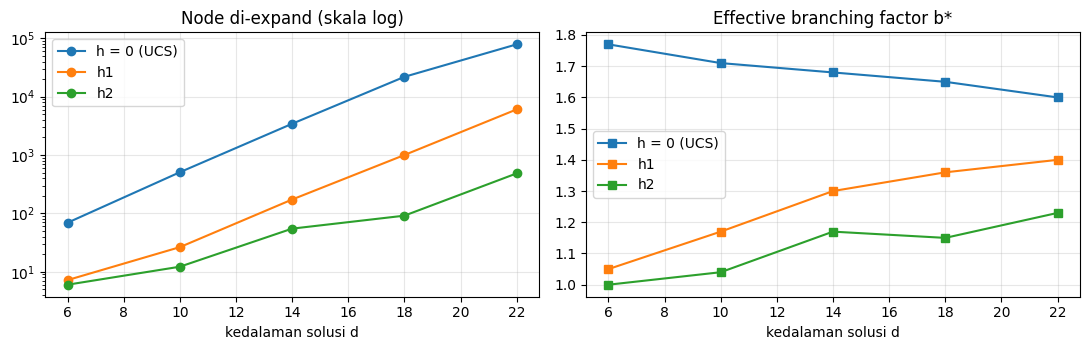

In [20]:
# Grafik pertumbuhan node dan effective branching factor
import statistics
KEDALAMAN = [6, 10, 14, 18, 22]
hasil = {"h = 0 (UCS)": [], "h1": [], "h2": []}
bstar = {"h = 0 (UCS)": [], "h1": [], "h2": []}
for d in KEDALAMAN:
    kasus = instans_acak(d, 5, 20260925 + d)
    for nama, hf in [("h = 0 (UCS)", h0_nol), ("h1", h1_salah_tempat), ("h2", h2_manhattan)]:
        jumlah = []
        for s in kasus:
            stats = {"expanded": 0}
            a_star_search(EightPuzzle(s), hf, stats)
            jumlah.append(stats["expanded"])
        m = statistics.mean(jumlah)
        hasil[nama].append(m)
        bstar[nama].append(effective_branching_factor(m, d))

fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
for nama in hasil:
    axes[0].plot(KEDALAMAN, hasil[nama], marker="o", label=nama)
    axes[1].plot(KEDALAMAN, bstar[nama], marker="s", label=nama)
axes[0].set_yscale("log"); axes[0].set_title("Node di-expand (skala log)")
axes[1].set_title("Effective branching factor b*")
for ax in axes:
    ax.set_xlabel("kedalaman solusi d"); ax.legend(); ax.grid(alpha=.3)
plt.tight_layout(); plt.show()

**Pertanyaan analisis Langkah 8:**
1. Berapa kali lipat penghematan A* dengan h₂ dibandingkan h = 0 pada d = 22?
2. Mengapa greedy best-first search pada tabel B justru meng-expand lebih banyak node daripada weighted A*?
3. Semua solusi weighted A* berada jauh di bawah batas W × C*. Mengapa batas itu tetap perlu dinyatakan?

*Jawaban:*

1. Pada d=22, rata-rata UCS (h=0) meng-expand 78.748 node, sedangkan A* dengan h₂ meng-expand 485 node. Penghematan ekspansi sekitar 78.748/485 = 162,4 kali.
2. Greedy hanya melihat h dan mengabaikan biaya g yang sudah ditempuh. Ia dapat mengikuti arah heuristik lokal yang tampak menjanjikan tetapi menjauh dari solusi. Weighted A* tetap mempertimbangkan g bersama bobot h, sehingga pada sampel ini ekspansinya lebih sedikit (rata-rata 354 dibanding 465 untuk greedy), walaupun tidak menjamin optimalitas.
3. Batas W × C* merupakan jaminan worst-case untuk Weighted A* dengan h admissible dan asumsi algoritma yang sesuai. Hasil percobaan yang lebih baik tidak menghilangkan kebutuhan jaminan tersebut, sebab instans lain dapat membuat biaya solusi mendekati batas.

## E. Tugas Praktikum

### Tugas 1
Ganti pasangan initial state dan goal state pada peta Sumatera Barat (misalnya **Painan → Lubuk Basung**). Bangun ulang
tabel heuristik dengan `buat_h_sld`, periksa admissibility dan consistency-nya, lalu bandingkan UCS, greedy, A*, dan IDA*.

**Hasil uji:** SLD ke Lubuk Basung admissible dan consistent. Semua algoritma menemukan rute Painan → Padang → Pariaman → Lubuk Basung dengan biaya 181 km. Greedy dan A* meng-expand 3 node, UCS 7 node, dan IDA* 9 node; dalam kasus ini rute Greedy kebetulan optimal.

In [21]:
h_lb = buat_h_sld("Lubuk Basung")
masalah_t1 = Problem("Painan", "Lubuk Basung", PETA_SUMBAR)

h_bintang_lb = {}
for kota in PETA_SUMBAR:
    hasil_ucs = uniform_cost_search(
        Problem(kota, "Lubuk Basung", PETA_SUMBAR), {"expanded": 0}
    )
    h_bintang_lb[kota] = hasil_ucs.path_cost

laporan_lb = periksa_heuristik(PETA_SUMBAR, h_lb.tabel, h_bintang_lb)
print("Heuristik ke Lubuk Basung — admissible:", laporan_lb["admissible"],
      "| consistent:", laporan_lb["consistent"])
print("Pelanggaran:", laporan_lb["pelanggaran"] or "tidak ada")
tabel_h_lb = pd.DataFrame([
    {"Kota": kota, "h(n)": h_lb.tabel[kota], "h*(n)": h_bintang_lb[kota]}
    for kota in sorted(PETA_SUMBAR, key=lambda k: h_lb.tabel[k])
])
display(tabel_h_lb)

tabel_tugas1 = ringkas(masalah_t1, h_lb, [
    ("UCS (f=g)", uniform_cost),
    ("Greedy (f=h)", greedy_best_first_search),
    ("A* (f=g+h)", a_star_search),
    ("IDA*", ida_star_search),
])
display(tabel_tugas1)

Heuristik ke Lubuk Basung — admissible: True | consistent: True
Pelanggaran: tidak ada


,Kota,h(n),h*(n)
0,Lubuk Basung,0,0
1,Pariaman,37,48
2,Bukittinggi,37,56
3,Padang Panjang,45,75
4,Batusangkar,64,111
5,Payakumbuh,67,89
6,Padang,83,104
7,Solok,87,166
8,Sawahlunto,93,157
9,Sijunjung,111,207


,Algoritma,Rute,Langkah,Biaya (km),Node di-expand,Frontier maks
0,UCS (f=g),Painan - Padang - Pariaman - Lubuk Basung,3,181,7,5
1,Greedy (f=h),Painan - Padang - Pariaman - Lubuk Basung,3,181,3,3
2,A* (f=g+h),Painan - Padang - Pariaman - Lubuk Basung,3,181,3,3
3,IDA*,Painan - Padang - Pariaman - Lubuk Basung,3,181,9,4


### Tugas 2
Buat heuristik yang **tidak admissible** dengan mengalikan h_SLD dengan 1,5 (meniru *detour index*). Jalankan A* dan catat
biaya solusi serta jumlah ekspansinya. Apakah solusinya masih optimal? Berapa penghematan nodenya?

**Hasil uji:** Untuk tujuan template Payakumbuh, h_detour melanggar admissibility (misalnya h(Bukittinggi)=45 km, sedangkan h*=33 km). Pada uji Padang–Payakumbuh, A* biasa dan A* detour sama-sama menghasilkan biaya 124 km dan meng-expand 3 node, sehingga penghematan pada contoh ini 0% dan solusi yang ditemukan tetap optimal. Namun karena heuristik tidak admissible, optimalitas tidak lagi dijamin untuk semua kasus.

In [22]:
def buat_h_detour(goal, faktor=1.5):
    dasar = buat_h_sld(goal)
    def hd(node):
        return faktor * dasar(node)
    hd.tabel = {k: faktor * v for k, v in dasar.tabel.items()}
    return hd

# Gunakan tujuan template Payakumbuh agar pengali 1,5 benar-benar melanggar
# admissibility: h(Bukittinggi)=45 km, sedangkan h*(Bukittinggi)=33 km.
masalah_t2 = Problem("Padang", "Payakumbuh", PETA_SUMBAR)
h_payakumbuh = buat_h_sld("Payakumbuh")
h_detour = buat_h_detour("Payakumbuh", faktor=1.5)
h_bintang_payakumbuh = {
    kota: uniform_cost_search(
        Problem(kota, "Payakumbuh", PETA_SUMBAR), {"expanded": 0}
    ).path_cost
    for kota in PETA_SUMBAR
}
cek_detour = periksa_heuristik(
    PETA_SUMBAR, h_detour.tabel, h_bintang_payakumbuh
)
print("Detour heuristic admissible:", cek_detour["admissible"])
print("Contoh pelanggaran:", next(
    (p for p in cek_detour["pelanggaran"] if "Bukittinggi" in p),
    "tidak ditemukan"
))

hasil_t2 = []
for nama, heuristic in [("A* h-SLD", h_payakumbuh), ("A* h-detour (W=1,5)", h_detour)]:
    stats = {"expanded": 0, "max_frontier": 0}
    hasil = a_star_search(masalah_t2, heuristic, stats)
    hasil_t2.append({
        "Algoritma": nama,
        "Rute": " -> ".join(path_states(hasil)),
        "Biaya solusi (km)": hasil.path_cost,
        "Node diekspansi": stats["expanded"],
        "Frontier maksimum": stats["max_frontier"],
    })
tabel_tugas2 = pd.DataFrame(hasil_t2)
display(tabel_tugas2)
ekspansi_awal, ekspansi_detour = [row["Node diekspansi"] for row in hasil_t2]
print("Penghematan ekspansi:", ekspansi_awal - ekspansi_detour,
      f"({(ekspansi_awal - ekspansi_detour) / ekspansi_awal * 100:.1f}%)")
print("Solusi detour optimal:",
      hasil_t2[1]["Biaya solusi (km)"] == hasil_t2[0]["Biaya solusi (km)"])

Detour heuristic admissible: False
Contoh pelanggaran: admissible: h(Bukittinggi)=45.0 > h*=33


,Algoritma,Rute,Biaya solusi (km),Node diekspansi,Frontier maksimum
0,A* h-SLD,Padang -> Padang Panjang -> Bukittinggi -> Pay...,124,3,6
1,"A* h-detour (W=1,5)",Padang -> Padang Panjang -> Bukittinggi -> Pay...,124,3,6


Penghematan ekspansi: 0 (0.0%)
Solusi detour optimal: True


### Tugas 3
Tambahkan pencatatan `max_frontier` pada IDA* (kedalaman maksimum stack rekursi aktif) dan bandingkan pemakaian memorinya
dengan A* pada instans 8-puzzle d = 22. Kaitkan hasilnya dengan Subbab 4.5.2.

**Hasil uji (5 instans, seluruh biaya solusi 22):** rata-rata A* meng-expand 484,6 node dengan frontier maksimum 287,8 node; IDA* meng-expand 773,4 node dengan stack aktif maksimum 23. IDA* menghemat memori secara nyata dengan kebutuhan yang mengikuti kedalaman solusi, tetapi dapat mengulang ekspansi pada iterasi batas f.

In [23]:
kasus_d22 = instans_acak(22, 5, 20260925 + 22)
hasil_tugas3 = []
for indeks, state in enumerate(kasus_d22, start=1):
    for nama, fungsi in [
        ("A* h2", lambda p, s: a_star_search(p, h2_manhattan, s)),
        ("IDA* h2", lambda p, s: ida_star_search(p, h2_manhattan, s)),
    ]:
        stats = {"expanded": 0, "max_frontier": 0}
        t0 = time.perf_counter()
        hasil = fungsi(EightPuzzle(state), stats)
        waktu_ms = (time.perf_counter() - t0) * 1000
        hasil_tugas3.append({
            "Instans": indeks,
            "Algoritma": nama,
            "Biaya solusi": hasil.path_cost,
            "Node diekspansi": stats["expanded"],
            "Frontier / stack maks.": stats["max_frontier"],
            "Waktu (ms)": round(waktu_ms, 2),
        })

tabel_tugas3 = pd.DataFrame(hasil_tugas3)
display(tabel_tugas3)
display(tabel_tugas3.groupby("Algoritma").mean(numeric_only=True).round(2))

,Instans,Algoritma,Biaya solusi,Node diekspansi,Frontier / stack maks.,Waktu (ms)
0,1,A* h2,22,344,203,6.38
1,1,IDA* h2,22,1003,23,12.04
2,2,A* h2,22,424,268,8.27
3,2,IDA* h2,22,586,23,6.95
4,3,A* h2,22,740,440,14.16
5,3,IDA* h2,22,696,23,8.18
6,4,A* h2,22,266,162,5.76
7,4,IDA* h2,22,473,23,5.64
8,5,A* h2,22,649,366,12.69
9,5,IDA* h2,22,1109,23,13.33


,Instans,Biaya solusi,Node diekspansi,Frontier / stack maks.,Waktu (ms)
Algoritma,,,,,
A* h2,3.0,22.0,484.6,287.8,9.45
IDA* h2,3.0,22.0,773.4,23.0,9.23


### Tugas 4
Buat heuristik ketiga untuk 8-puzzle, yaitu **h₃ = max(h₁, h₂)**. Buktikan secara empiris bahwa h₃ tidak pernah lebih buruk
daripada h₂, lalu jelaskan mengapa demikian dengan konsep *dominance*.

**Hasil uji:** Pada 25 instans di lima kedalaman, h₃ tidak pernah meng-expand node lebih banyak daripada h₂. Untuk 8-puzzle, h₂ (Manhattan) selalu setidaknya sebesar h₁ (ubin salah tempat), sehingga max(h₁,h₂)=h₂; hasil seri ini sesuai dengan dominance.

In [24]:
def h3_maks(node):
    """Heuristik gabungan h3 = max(h1, h2)."""
    return max(h1_salah_tempat(node), h2_manhattan(node))

hasil_tugas4 = []
for d in (6, 10, 14, 18, 22):
    states = instans_acak(d, 5, 20260925 + d)
    ekspansi_h2 = []
    ekspansi_h3 = []
    for state in states:
        for nama, heuristic, hasil_list in [
            ("A* h2", h2_manhattan, ekspansi_h2),
            ("A* h3=max(h1,h2)", h3_maks, ekspansi_h3),
        ]:
            stats = {"expanded": 0, "max_frontier": 0}
            hasil = a_star_search(EightPuzzle(state), heuristic, stats)
            hasil_list.append(stats["expanded"])
            hasil_tugas4.append({
                "Kedalaman d": d,
                "Instans": len(ekspansi_h2) if hasil_list is ekspansi_h2 else len(ekspansi_h3),
                "Algoritma": nama,
                "Node diekspansi": stats["expanded"],
                "Biaya solusi": hasil.path_cost,
            })
    assert all(h3 <= h2 for h2, h3 in zip(ekspansi_h2, ekspansi_h3))

tabel_tugas4 = pd.DataFrame(hasil_tugas4)
display(tabel_tugas4.groupby(["Kedalaman d", "Algoritma"])[
    ["Node diekspansi", "Biaya solusi"]
].mean().round(2))
print("Kasus h3 tidak lebih buruk dari h2:",
      sum(1 for row in hasil_tugas4 if row["Algoritma"] == "A* h3=max(h1,h2)") ,
      "dari", sum(1 for row in hasil_tugas4 if row["Algoritma"] == "A* h3=max(h1,h2)"))
print("Pada 8-puzzle, h2 Manhattan selalu >= h1 ubin salah tempat; karena itu h3=max(h1,h2)=h2.")

Node diekspansi  Biaya solusi
Kedalaman d Algoritma                                      
6           A* h2                         6.0           6.0
            A* h3=max(h1,h2)              6.0           6.0
10          A* h2                        12.2          10.0
            A* h3=max(h1,h2)             12.2          10.0
14          A* h2                        54.8          14.0
            A* h3=max(h1,h2)             54.8          14.0
18          A* h2                        91.4          18.0
            A* h3=max(h1,h2)             91.4          18.0
22          A* h2                       484.6          22.0
            A* h3=max(h1,h2)            484.6          22.0

Kasus h3 tidak lebih buruk dari h2: 25 dari 25
Pada 8-puzzle, h2 Manhattan selalu >= h1 ubin salah tempat; karena itu h3=max(h1,h2)=h2.


### Tugas 5 (Pengayaan)
Implementasikan **beam search** dengan lebar k (misalnya k = 5, 10, 50) pada 8-puzzle. Ukur hubungan antara nilai k,
biaya solusi, jumlah node, dan tingkat keberhasilan menemukan solusi. Eksperimen menggunakan lima instans solvable berkedalaman optimal 22.

**Hasil uji:** Untuk k=5, 10, dan 50, beam menemukan solusi pada 5/5 instans. Rata-rata biaya solusi berturut-turut 64,8; 34,8; dan 26,4 langkah (optimalnya 22), sedangkan rata-rata ekspansi 310,8; 315,2; dan 1.016,8. Beam yang lebih lebar memberi solusi lebih baik pada sampel ini, tetapi membutuhkan lebih banyak ekspansi dan tetap tidak menjamin optimalitas.

In [25]:
def beam_search(problem, h, k, stats, batas_iterasi=10000):
    """Beam search lebar k; mengembalikan solusi atau None bila beam buntu."""
    if k < 1:
        raise ValueError("Lebar beam k harus minimal 1")
    stats.setdefault("expanded", 0)
    stats.setdefault("max_frontier", 0)
    awal = Node(problem.initial)
    if problem.is_goal(awal.state):
        stats["max_frontier"] = max(stats["max_frontier"], 1)
        return awal
    beam = [awal]
    reached = {awal.state}
    stats["max_frontier"] = max(stats["max_frontier"], 1)
    while beam and stats["expanded"] < batas_iterasi:
        candidates = {}
        for node in beam:
            if stats["expanded"] >= batas_iterasi:
                break
            stats["expanded"] += 1
            for child in expand(problem, node):
                if child.state in reached:
                    continue
                reached.add(child.state)
                if problem.is_goal(child.state):
                    stats["max_frontier"] = max(stats["max_frontier"], len(candidates) + 1)
                    return child
                candidates[child.state] = child
        beam = sorted(candidates.values(), key=lambda n: (h(n), n.state))[:k]
        stats["max_frontier"] = max(stats["max_frontier"], len(beam))
    return None

kasus_beam = instans_acak(22, 5, 20260925 + 22)
hasil_tugas5 = []
for k in (5, 10, 50):
    berhasil = 0
    biaya_berhasil = []
    ekspansi = []
    for indeks, state in enumerate(kasus_beam, start=1):
        stats = {"expanded": 0, "max_frontier": 0}
        hasil = beam_search(EightPuzzle(state), h2_manhattan, k, stats)
        ekspansi.append(stats["expanded"])
        if hasil is not None:
            berhasil += 1
            biaya_berhasil.append(hasil.path_cost)
        hasil_tugas5.append({
            "k": k,
            "Instans": indeks,
            "Berhasil": hasil is not None,
            "Biaya solusi": hasil.path_cost if hasil else None,
            "Node diekspansi": stats["expanded"],
            "Frontier maksimum": stats["max_frontier"],
        })
    print(f"k={k}: berhasil {berhasil}/{len(kasus_beam)}, "
          f"biaya rata-rata sukses={sum(biaya_berhasil) / len(biaya_berhasil) if biaya_berhasil else '—'}, "
          f"rata-rata ekspansi={sum(ekspansi) / len(ekspansi):.1f}")
tabel_tugas5 = pd.DataFrame(hasil_tugas5)
display(tabel_tugas5)

k=5: berhasil 5/5, biaya rata-rata sukses=64.8, rata-rata ekspansi=310.8
k=10: berhasil 5/5, biaya rata-rata sukses=34.8, rata-rata ekspansi=315.2
k=50: berhasil 5/5, biaya rata-rata sukses=26.4, rata-rata ekspansi=1016.8


,k,Instans,Berhasil,Biaya solusi,Node diekspansi,Frontier maksimum
0,5,1,True,38,176,5
1,5,2,True,100,486,5
2,5,3,True,54,259,5
3,5,4,True,96,465,5
4,5,5,True,36,168,5
5,10,1,True,26,226,10
6,10,2,True,42,386,10
7,10,3,True,30,272,10
8,10,4,True,22,186,10
9,10,5,True,54,506,10


### Tugas 6 (Pengayaan)
Gunakan graph kampus PNP dari Tugas 6 Praktikum 3. Rancang heuristik berdasarkan koordinat denah (boleh koordinat kira-kira
dalam meter), periksa admissibility-nya, lalu bandingkan A* dengan UCS.

**Hasil uji:** Heuristik Euclidean pada 13 lokasi memenuhi admissibility dan consistency. UCS dan A* sama-sama menemukan rute Gerbang Utama → Parkiran Utama → Perpustakaan → Masjid Kampus dengan biaya 350 m; UCS meng-expand 10 node dan A* 8 node.

In [26]:
KAMPUS_PNP = {
    "Gerbang Utama": {"Parkiran Utama": 80, "Gedung Kuliah A": 150, "Gerbang Samping": 200},
    "Parkiran Utama": {"Gerbang Utama": 80, "Gedung Kuliah A": 90, "Perpustakaan": 180},
    "Gedung Kuliah A": {"Gerbang Utama": 150, "Parkiran Utama": 90, "Gedung Kuliah B": 100, "Lab Komputer": 70},
    "Gedung Kuliah B": {"Gedung Kuliah A": 100, "Perpustakaan": 120, "Gedung Jurusan TI": 80},
    "Lab Komputer": {"Gedung Kuliah A": 70, "Gedung Jurusan TI": 60, "Kantin": 130},
    "Gedung Jurusan TI": {"Gedung Kuliah B": 80, "Lab Komputer": 60, "Perpustakaan": 100, "Masjid Kampus": 140},
    "Perpustakaan": {"Parkiran Utama": 180, "Gedung Kuliah B": 120, "Gedung Jurusan TI": 100, "Masjid Kampus": 90, "Auditorium": 160},
    "Masjid Kampus": {"Gedung Jurusan TI": 140, "Perpustakaan": 90, "Kantin": 110, "Auditorium": 100},
    "Kantin": {"Lab Komputer": 130, "Masjid Kampus": 110, "Parkiran Belakang": 120},
    "Auditorium": {"Perpustakaan": 160, "Masjid Kampus": 100, "Parkiran Belakang": 140},
    "Parkiran Belakang": {"Kantin": 120, "Auditorium": 140, "Lapangan": 100},
    "Lapangan": {"Parkiran Belakang": 100, "Gerbang Samping": 130},
    "Gerbang Samping": {"Lapangan": 130, "Gerbang Utama": 200},
}

# Koordinat ilustratif dalam meter; semua ruas dibuat lebih panjang dari
# jarak Euclidean antartitik agar jarak garis lurus tetap admissible.
KOORDINAT_KAMPUS = {
    "Gerbang Utama": (0, 0), "Parkiran Utama": (40, 0),
    "Gedung Kuliah A": (80, 20), "Gedung Kuliah B": (120, 30),
    "Lab Komputer": (90, 60), "Gedung Jurusan TI": (130, 70),
    "Perpustakaan": (160, 30), "Masjid Kampus": (190, 40),
    "Kantin": (160, 90), "Auditorium": (220, 60),
    "Parkiran Belakang": (250, 80), "Lapangan": (280, 50),
    "Gerbang Samping": (180, 0),
}

def h_kampus(node):
    x, y = KOORDINAT_KAMPUS[node.state]
    gx, gy = KOORDINAT_KAMPUS["Masjid Kampus"]
    return math.hypot(x - gx, y - gy)

masalah_kampus = Problem("Gerbang Utama", "Masjid Kampus", KAMPUS_PNP)
hstar_kampus = {
    lokasi: uniform_cost_search(
        Problem(lokasi, masalah_kampus.goal, KAMPUS_PNP), {"expanded": 0}
    ).path_cost
    for lokasi in KAMPUS_PNP
}
tabel_h_kampus = {lokasi: h_kampus(Node(lokasi)) for lokasi in KAMPUS_PNP}
laporan_kampus = periksa_heuristik(KAMPUS_PNP, tabel_h_kampus, hstar_kampus)
print("Lokasi:", len(KAMPUS_PNP), "| admissible:", laporan_kampus["admissible"],
      "| consistent:", laporan_kampus["consistent"])
print("Pelanggaran:", laporan_kampus["pelanggaran"] or "tidak ada")

hasil_kampus = []
for nama, fungsi in [("UCS", uniform_cost), ("A* Euclidean", a_star_search)]:
    stats = {"expanded": 0, "max_frontier": 0}
    hasil = fungsi(masalah_kampus, h_kampus if nama.startswith("A*") else h0_nol, stats)
    hasil_kampus.append({
        "Algoritma": nama,
        "Rute": " → ".join(path_states(hasil)),
        "Biaya (meter)": hasil.path_cost,
        "Node diekspansi": stats["expanded"],
        "Frontier maksimum": stats["max_frontier"],
    })
display(pd.DataFrame(hasil_kampus))
display(pd.DataFrame([
    {"Lokasi": lokasi, "h(n) garis lurus (m)": round(tabel_h_kampus[lokasi], 1),
     "h*(n) biaya optimal (m)": hstar_kampus[lokasi]}
    for lokasi in KAMPUS_PNP
]))

Lokasi: 13 | admissible: True | consistent: True
Pelanggaran: tidak ada


,Algoritma,Rute,Biaya (meter),Node diekspansi,Frontier maksimum
0,UCS,Gerbang Utama → Parkiran Utama → Perpustakaan ...,350,10,5
1,A* Euclidean,Gerbang Utama → Parkiran Utama → Perpustakaan ...,350,8,7


,Lokasi,h(n) garis lurus (m),h*(n) biaya optimal (m)
0,Gerbang Utama,194.2,350
1,Parkiran Utama,155.2,270
2,Gedung Kuliah A,111.8,270
3,Gedung Kuliah B,70.7,210
4,Lab Komputer,102.0,200
5,Gedung Jurusan TI,67.1,140
6,Perpustakaan,31.6,90
7,Masjid Kampus,0.0,0
8,Kantin,58.3,110
9,Auditorium,36.1,100


## F. Kesimpulan
Kaitkan hasil empiris pada notebook ini dengan konsep Bab 4: admissibility, consistency, pruning, dominance,
effective branching factor, serta pertukaran antara optimalitas, waktu, dan memori (Tabel 4.7).

*Kesimpulan:* Heuristik SLD yang dibulatkan ke bawah pada peta Sumatera Barat memenuhi admissibility dan consistency untuk tujuan yang diuji, sehingga A* mempertahankan optimalitas biaya. A* dapat memangkas ekspansi dibanding UCS; kualitas heuristik yang lebih informatif menurunkan effective branching factor. IDA* menukar waktu/ekspansi ulang dengan kebutuhan memori yang sebanding kedalaman solusi. Heuristik h₃=max(h₁,h₂) mendominasi setiap komponennya; pada 8-puzzle, h₂ Manhattan sendiri selalu setidaknya sebesar h₁ sehingga h₃ sama dengan h₂. Beam search membatasi lebar frontier dan dapat mengurangi kerja, tetapi tidak lengkap maupun optimal karena state yang dipangkas dapat menjadi bagian jalur solusi. Weighted A* dan greedy dapat menghemat ekspansi pada sebagian instans, dengan risiko solusi lebih mahal. Pada graph kampus, Euclidean distance dari koordinat yang dibuat konsisten dengan bobot sisi menjadi heuristik admissible dan A* dapat dibandingkan langsung dengan UCS.

---
**Pernyataan penggunaan AI generatif** (isi jika ada, sesuai ketentuan RPS):

**Rujukan:** Russell, S. J., & Norvig, P. (2022). *Artificial intelligence: A modern approach* (Ed. ke-4, Global Edition).
Pearson. Bab 3, Subbab 3.5–3.6.